# DenseNet169 — Experiment D
## Real Training → Synthetic Validation → Untouched Real Test

**Purpose:** Evaluate cross-domain validation behavior while keeping the final real test set completely independent from model selection.

**Important:** Synthetic validation is used only for monitoring/model selection. The real test set is never used during training or checkpoint selection.

# Can a model trained only on real MRI images maintain its performance when model selection is performed using synthetic MRI images?

In [1]:
# ==========================================================
# 0. REPRODUCIBILITY + DATASET PATHS
# ==========================================================
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

REAL_DIR = (
    "/kaggle/input/datasets/ramanarasimhakanduri/"
    "brain-tumour-dataset/final_dataset_clean"
)

SYNTHETIC_DIR = (
    "/kaggle/input/datasets/shuvosingh/"
    "mri-syntheticdata/prepared_dataset"
)

SYNTHETIC_VAL_DIR = os.path.join(SYNTHETIC_DIR, "val")
SYNTHETIC_TEST_DIR = os.path.join(SYNTHETIC_DIR, "test")

IMG_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

print("=" * 70)
print("DATASET PATH CHECK")
print("=" * 70)
for name, path in [
    ("Real dataset", REAL_DIR),
    ("Synthetic dataset", SYNTHETIC_DIR),
    ("Synthetic validation", SYNTHETIC_VAL_DIR),
    ("Synthetic test", SYNTHETIC_TEST_DIR),
]:
    print(f"{name:22s}: {path}")
    print(f"Exists: {os.path.isdir(path)}\n")

for path in [REAL_DIR, SYNTHETIC_VAL_DIR]:
    if not os.path.isdir(path):
        raise FileNotFoundError(f"Required dataset path not found: {path}")


DATASET PATH CHECK
Real dataset          : /kaggle/input/datasets/ramanarasimhakanduri/brain-tumour-dataset/final_dataset_clean
Exists: True

Synthetic dataset     : /kaggle/input/datasets/shuvosingh/mri-syntheticdata/prepared_dataset
Exists: True

Synthetic validation  : /kaggle/input/datasets/shuvosingh/mri-syntheticdata/prepared_dataset/val
Exists: True

Synthetic test        : /kaggle/input/datasets/shuvosingh/mri-syntheticdata/prepared_dataset/test
Exists: True



In [2]:
# ==========================================================
# 1. VERIFY CLASSES + BUILD DATAFRAMES
# ==========================================================
from sklearn.model_selection import train_test_split

classes = sorted([
    d for d in os.listdir(REAL_DIR)
    if os.path.isdir(os.path.join(REAL_DIR, d))
])

synthetic_val_classes = sorted([
    d for d in os.listdir(SYNTHETIC_VAL_DIR)
    if os.path.isdir(os.path.join(SYNTHETIC_VAL_DIR, d))
])

print("=" * 70)
print("CLASS CONSISTENCY CHECK")
print("=" * 70)
print("Real classes           :", classes)
print("Synthetic val classes  :", synthetic_val_classes)

if classes != synthetic_val_classes:
    raise ValueError(
        "Real and synthetic validation class folders do not match.\n"
        f"Real: {classes}\nSynthetic: {synthetic_val_classes}"
    )

# Collect real images
real_records = []
for cls in classes:
    class_dir = os.path.join(REAL_DIR, cls)
    for filename in sorted(os.listdir(class_dir)):
        if filename.lower().endswith(IMG_EXTS):
            real_records.append([os.path.join(class_dir, filename), cls])

real_df = pd.DataFrame(real_records, columns=["filepaths", "labels"])

# IMPORTANT: real test is held out from all training/model-selection operations.
real_train_df, real_test_df = train_test_split(
    real_df,
    test_size=0.20,
    stratify=real_df["labels"],
    random_state=SEED,
)

real_train_df = real_train_df.reset_index(drop=True)
real_test_df = real_test_df.reset_index(drop=True)

# Collect synthetic validation images only.
synthetic_records = []
for cls in classes:
    class_dir = os.path.join(SYNTHETIC_VAL_DIR, cls)
    if not os.path.isdir(class_dir):
        raise FileNotFoundError(f"Missing synthetic validation class: {cls}")
    for filename in sorted(os.listdir(class_dir)):
        if filename.lower().endswith(IMG_EXTS):
            synthetic_records.append([os.path.join(class_dir, filename), cls])

synthetic_val_df = pd.DataFrame(
    synthetic_records,
    columns=["filepaths", "labels"]
).reset_index(drop=True)

print("\n" + "=" * 70)
print("EXPERIMENT D SPLIT")
print("=" * 70)
print(f"Real train          : {len(real_train_df)}")
print(f"Synthetic validation: {len(synthetic_val_df)}")
print(f"Real test           : {len(real_test_df)}")

print("\nClass-wise distribution:")
for cls in classes:
    print(
        f"{cls:15s} | "
        f"Train: {(real_train_df.labels == cls).sum():4d} | "
        f"Synthetic Val: {(synthetic_val_df.labels == cls).sum():4d} | "
        f"Real Test: {(real_test_df.labels == cls).sum():4d}"
    )


CLASS CONSISTENCY CHECK
Real classes           : ['glioma', 'meningioma', 'notumor', 'pituitary']
Synthetic val classes  : ['glioma', 'meningioma', 'notumor', 'pituitary']

EXPERIMENT D SPLIT
Real train          : 5513
Synthetic validation: 1115
Real test           : 1379

Class-wise distribution:
glioma          | Train: 1387 | Synthetic Val:  280 | Real Test:  347
meningioma      | Train: 1300 | Synthetic Val:  264 | Real Test:  325
notumor         | Train: 1496 | Synthetic Val:  302 | Real Test:  374
pituitary       | Train: 1330 | Synthetic Val:  269 | Real Test:  333


In [9]:
# ==========================================================
# EFFICIENTNETB0 MODEL
# ==========================================================

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.optimizers import Adam

INPUT_SHAPE = (224, 224, 3)
NUM_CLASSES = len(train_gen.class_indices)

print("=" * 70)
print("EFFICIENTNETB0")
print("=" * 70)

print("Classes:", train_gen.class_indices)
print("Number of classes:", NUM_CLASSES)

# ==========================================================
# LOAD IMAGENET PRETRAINED EFFICIENTNETB0
# ==========================================================

print("\nLoading ImageNet pretrained EfficientNetB0...")

base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=INPUT_SHAPE
)

print("✓ ImageNet pretrained weights loaded successfully.")

# ==========================================================
# FREEZE BACKBONE - STAGE 1
# ==========================================================

base_model.trainable = False

# ==========================================================
# CLASSIFICATION HEAD
# ==========================================================

inputs = layers.Input(shape=INPUT_SHAPE)

x = base_model(
    inputs,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.30)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = models.Model(
    inputs=inputs,
    outputs=outputs
)

# ==========================================================
# COMPILE
# ==========================================================

model.compile(
    optimizer=Adam(
        learning_rate=1e-3
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# ==========================================================
# MODEL INFORMATION
# ==========================================================

print("\n" + "=" * 70)
print("MODEL INFORMATION")
print("=" * 70)

print("Architecture       : EfficientNetB0")
print("Input shape        :", INPUT_SHAPE)
print("Number of classes  :", NUM_CLASSES)
print("Output shape       :", model.output_shape)
print("Backbone status    : FROZEN")
print("Learning rate      : 1e-3")
print("Pretrained weights : ImageNet")

print("=" * 70)

model.summary()

EFFICIENTNETB0
Classes: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Number of classes: 4

Loading ImageNet pretrained EfficientNetB0...
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✓ ImageNet pretrained weights loaded successfully.

MODEL INFORMATION
Architecture       : EfficientNetB0
Input shape        : (224, 224, 3)
Number of classes  : 4
Output shape       : (None, 4)
Backbone status    : FROZEN
Learning rate      : 1e-3
Pretrained weights : ImageNet


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,059,815 (15.49 MB)

 Trainable params: 7,684 (30.02 KB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [11]:
# ==========================================================
# 4. TRAINING — REAL TRAIN → SYNTHETIC VALIDATION
# ==========================================================
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint

CHECKPOINT_DIR = "/kaggle/working"
STAGE1_BEST = os.path.join(CHECKPOINT_DIR, "DenseNet169_stage1_best.keras")
FINAL_BEST = os.path.join(CHECKPOINT_DIR, "DenseNet169_final_best.keras")

# -----------------------------
# Stage 1: frozen backbone
# -----------------------------
print("=" * 70)
print("STAGE 1: FROZEN BACKBONE (EPOCHS 1–5)")
print("=" * 70)

callbacks_stage1 = [
    ReduceLROnPlateau(
        monitor="val_loss", factor=0.3, patience=2,
        min_lr=1e-7, verbose=1
    ),
    ModelCheckpoint(
        STAGE1_BEST, monitor="val_accuracy", mode="max",
        save_best_only=True, verbose=1
    ),
]

history_stage1 = model.fit(
    train_gen,
    validation_data=synthetic_val_gen,
    epochs=5,
    callbacks=callbacks_stage1,
    verbose=1,
)

# CRITICAL FIX:
# Start fine-tuning from the BEST Stage-1 model, not merely the last Stage-1 epoch.
model = tf.keras.models.load_model(STAGE1_BEST)

# Recover the backbone from the loaded model.
base_model = model.get_layer("densenet169")
base_model.trainable = True

# Freeze early layers; keep BatchNorm frozen for stable transfer learning.
FINE_TUNE_FROM = 400
for layer in base_model.layers[:FINE_TUNE_FROM]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

print("\n" + "=" * 70)
print("STAGE 2: FINE-TUNING (EPOCHS 6–15)")
print("=" * 70)
print("Trainable DenseNet layers:", sum(layer.trainable for layer in base_model.layers))

callbacks_stage2 = [
    ReduceLROnPlateau(
        monitor="val_loss", factor=0.3, patience=2,
        min_lr=1e-7, verbose=1
    ),
    ModelCheckpoint(
        FINAL_BEST, monitor="val_accuracy", mode="max",
        save_best_only=True, verbose=1
    ),
]

history_stage2 = model.fit(
    train_gen,
    validation_data=synthetic_val_gen,
    initial_epoch=5,
    epochs=15,
    callbacks=callbacks_stage2,
    verbose=1,
)

# Combine histories safely.
history = type("History", (), {})()
history.history = {}
for key in history_stage1.history:
    history.history[key] = (
        history_stage1.history[key] + history_stage2.history.get(key, [])
    )

print("\nTraining complete.")
print("Best checkpoint:", FINAL_BEST)


STAGE 1: FROZEN BACKBONE (EPOCHS 1–5)
Epoch 1/5
  1/173 ━━━━━━━━━━━━━━━━━━━━ 2:10:52 46s/step - accuracy: 0.4062 - loss: 1.3510

I0000 00:00:1787333906.822096     134 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


173/173 ━━━━━━━━━━━━━━━━━━━━ 0s 616ms/step - accuracy: 0.5993 - loss: 0.9800
Epoch 1: val_accuracy improved from None to 0.72825, saving model to /kaggle/working/DenseNet169_stage1_best.keras

Epoch 1: finished saving model to /kaggle/working/DenseNet169_stage1_best.keras
173/173 ━━━━━━━━━━━━━━━━━━━━ 199s 893ms/step - accuracy: 0.6788 - loss: 0.8178 - val_accuracy: 0.7283 - val_loss: 0.7539 - learning_rate: 0.0010
Epoch 2/5
173/173 ━━━━━━━━━━━━━━━━━━━━ 0s 419ms/step - accuracy: 0.7883 - loss: 0.5962
Epoch 2: val_accuracy improved from 0.72825 to 0.81256, saving model to /kaggle/working/DenseNet169_stage1_best.keras

Epoch 2: finished saving model to /kaggle/working/DenseNet169_stage1_best.keras
173/173 ━━━━━━━━━━━━━━━━━━━━ 78s 451ms/step - accuracy: 0.7845 - loss: 0.5977 - val_accuracy: 0.8126 - val_loss: 0.5622 - learning_rate: 0.0010
Epoch 3/5
173/173 ━━━━━━━━━━━━━━━━━━━━ 0s 408ms/step - accuracy: 0.8008 - loss: 0.5603
Epoch 3: val_accuracy did not improve from 0.81256
173/173 ━━━━━━

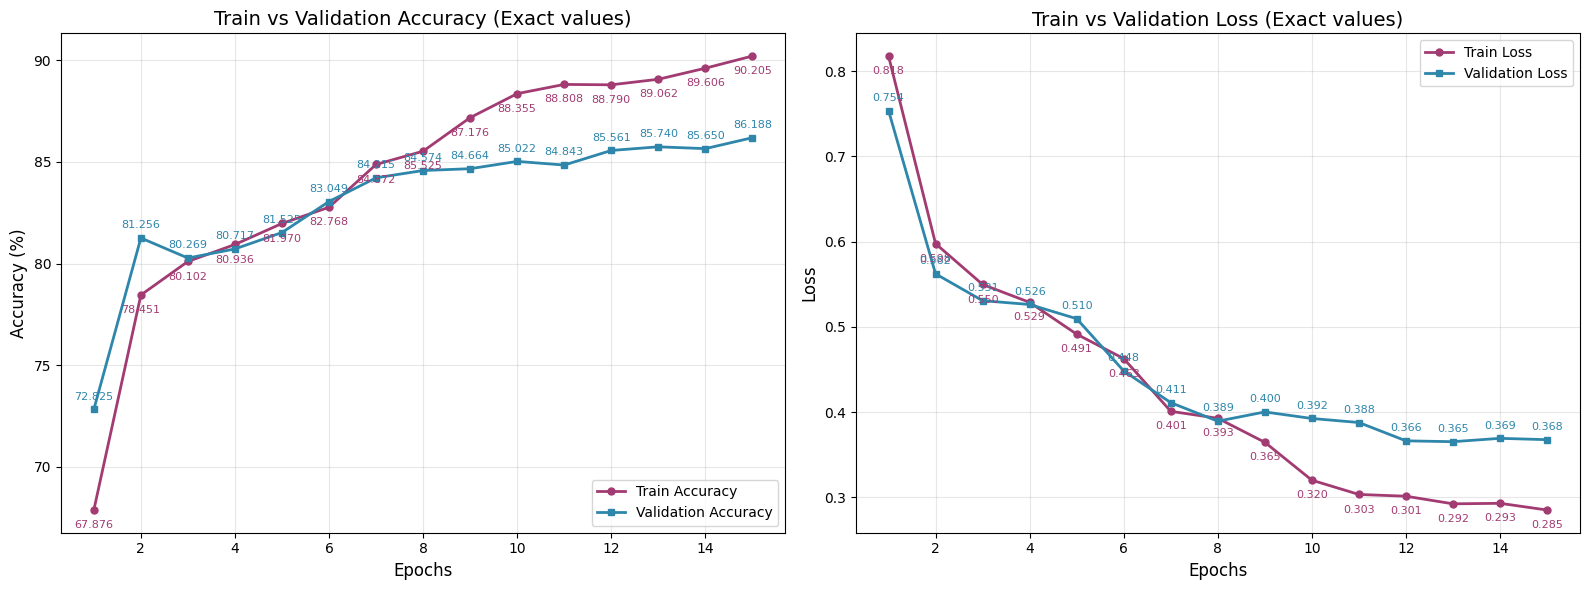

BEST SYNTHETIC-VALIDATION PERFORMANCE
Best Validation Accuracy : 86.188%
Best Accuracy Epoch      : 15
Lowest Validation Loss   : 0.3652
Lowest Loss Epoch        : 13


In [12]:
# ==========================================================
# 5. TRAINING / SYNTHETIC-VALIDATION CURVES
# JOURNAL STYLE — BLUE + PINK
# ==========================================================
import matplotlib.pyplot as plt

acc = np.array(history.history["accuracy"])
val_acc = np.array(history.history["val_accuracy"])
loss = np.array(history.history["loss"])
val_loss = np.array(history.history["val_loss"])
epochs = np.arange(1, len(acc) + 1)

TRAIN_COLOR = "#A23B72"
VAL_COLOR = "#2E86AB"

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
ax.plot(epochs, acc * 100, color=TRAIN_COLOR, marker="o", linewidth=2, markersize=5, label="Train Accuracy")
ax.plot(epochs, val_acc * 100, color=VAL_COLOR, marker="s", linewidth=2, markersize=5, label="Validation Accuracy")
for x, y in zip(epochs, acc * 100):
    ax.annotate(f"{y:.3f}", (x, y), textcoords="offset points", xytext=(0, -13), ha="center", fontsize=8, color=TRAIN_COLOR)
for x, y in zip(epochs, val_acc * 100):
    ax.annotate(f"{y:.3f}", (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8, color=VAL_COLOR)
ax.set_title("Train vs Validation Accuracy (Exact values)", fontsize=14)
ax.set_xlabel("Epochs", fontsize=12)
ax.set_ylabel("Accuracy (%)", fontsize=12)
ax.set_xticks(np.arange(2, len(epochs) + 1, 2))
ax.grid(True, alpha=0.3)
ax.legend(loc="lower right")

ax = axes[1]
ax.plot(epochs, loss, color=TRAIN_COLOR, marker="o", linewidth=2, markersize=5, label="Train Loss")
ax.plot(epochs, val_loss, color=VAL_COLOR, marker="s", linewidth=2, markersize=5, label="Validation Loss")
for x, y in zip(epochs, loss):
    ax.annotate(f"{y:.3f}", (x, y), textcoords="offset points", xytext=(0, -13), ha="center", fontsize=8, color=TRAIN_COLOR)
for x, y in zip(epochs, val_loss):
    ax.annotate(f"{y:.3f}", (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8, color=VAL_COLOR)
ax.set_title("Train vs Validation Loss (Exact values)", fontsize=14)
ax.set_xlabel("Epochs", fontsize=12)
ax.set_ylabel("Loss", fontsize=12)
ax.set_xticks(np.arange(2, len(epochs) + 1, 2))
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

best_val_acc = np.max(val_acc)
best_acc_epoch = np.argmax(val_acc) + 1
best_val_loss = np.min(val_loss)
best_loss_epoch = np.argmin(val_loss) + 1

print("=" * 60)
print("BEST SYNTHETIC-VALIDATION PERFORMANCE")
print("=" * 60)
print(f"Best Validation Accuracy : {best_val_acc * 100:.3f}%")
print(f"Best Accuracy Epoch      : {best_acc_epoch}")
print(f"Lowest Validation Loss   : {best_val_loss:.4f}")
print(f"Lowest Loss Epoch        : {best_loss_epoch}")


In [13]:
# ==========================================================
# 6. LOAD BEST CHECKPOINT BEFORE FINAL REAL TEST
# ==========================================================
from tensorflow.keras.models import load_model

if not os.path.exists(FINAL_BEST):
    raise FileNotFoundError(f"Best checkpoint not found: {FINAL_BEST}")

model = load_model(FINAL_BEST)
print("Best checkpoint loaded successfully:")
print(FINAL_BEST)


Best checkpoint loaded successfully:
/kaggle/working/DenseNet169_final_best.keras


In [14]:
# ==========================================================
# 7. FINAL REAL TEST PREDICTION — TEST IS UNTOUCHED
# ==========================================================
real_test_gen.reset()

preds = model.predict(real_test_gen, verbose=1)
y_pred = np.argmax(preds, axis=1)
y_true = real_test_gen.classes
class_names = list(real_test_gen.class_indices.keys())

assert len(y_true) == real_test_gen.samples
assert preds.shape == (real_test_gen.samples, len(class_names))

print("\n" + "=" * 70)
print("FINAL REAL TEST PREDICTION")
print("=" * 70)
print("Classes:", class_names)
print("Number of test samples:", len(y_true))
print("Prediction shape:", preds.shape)
print("Test generator shuffle:", real_test_gen.shuffle)


44/44 ━━━━━━━━━━━━━━━━━━━━ 48s 674ms/step

FINAL REAL TEST PREDICTION
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of test samples: 1379
Prediction shape: (1379, 4)
Test generator shuffle: False


In [15]:
# ==========================================================
# 8. PREDICTION DISTRIBUTION DIAGNOSTIC
# ==========================================================
print("=" * 70)
print("REAL TEST PREDICTION DISTRIBUTION")
print("=" * 70)

unique, counts = np.unique(y_pred, return_counts=True)
pred_counts = dict(zip(unique, counts))
for idx, name in enumerate(class_names):
    count = pred_counts.get(idx, 0)
    print(f"{name:15s}: {count:4d} images ({count / len(y_pred) * 100:6.2f}%)")


REAL TEST PREDICTION DISTRIBUTION
glioma         :  337 images ( 24.44%)
meningioma     :  245 images ( 17.77%)
notumor        :  373 images ( 27.05%)
pituitary      :  424 images ( 30.75%)


In [16]:
# ==========================================================
# 9. CLASSIFICATION REPORT
# ==========================================================
from sklearn.metrics import classification_report

print("=" * 70)
print("CLASSIFICATION REPORT — REAL TEST")
print("=" * 70)
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0,
    )
)


CLASSIFICATION REPORT — REAL TEST
              precision    recall  f1-score   support

      glioma     0.8991    0.8732    0.8860       347
  meningioma     0.8776    0.6615    0.7544       325
     notumor     0.9544    0.9519    0.9531       374
   pituitary     0.7807    0.9940    0.8745       333

    accuracy                         0.8738      1379
   macro avg     0.8779    0.8702    0.8670      1379
weighted avg     0.8804    0.8738    0.8704      1379



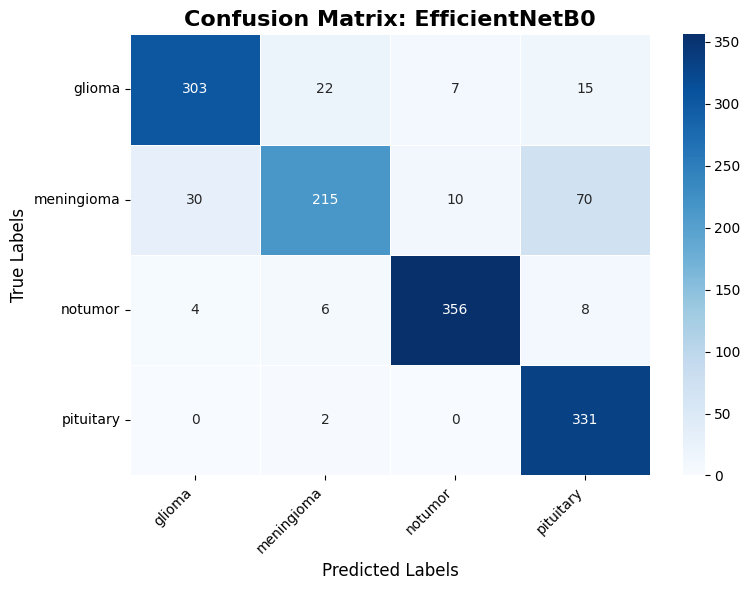

Confusion Matrix:

[[303  22   7  15]
 [ 30 215  10  70]
 [  4   6 356   8]
 [  0   2   0 331]]


In [17]:
# ==========================================================
# 10. CONFUSION MATRIX — JOURNAL STYLE
# ==========================================================
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True,
    linewidths=0.5,
    linecolor="white",
)
plt.title("Confusion Matrix: EfficientNetB0", fontsize=16, fontweight="bold")
plt.xlabel("Predicted Labels", fontsize=12)
plt.ylabel("True Labels", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("Confusion Matrix:\n")
print(cm)


In [18]:
# ==========================================================
# 11. FINAL METRICS + SPECIFICITY + MCC + INFERENCE
# ==========================================================
import time
from sklearn.metrics import matthews_corrcoef, accuracy_score, precision_recall_fscore_support

# Metrics from the already-computed final real-test predictions.
accuracy = accuracy_score(y_true, y_pred)
mcc = matthews_corrcoef(y_true, y_pred)

specificities = []
for i in range(len(class_names)):
    TP = cm[i, i]
    FP = cm[:, i].sum() - TP
    FN = cm[i, :].sum() - TP
    TN = cm.sum() - (TP + FP + FN)
    specificities.append(TN / (TN + FP) if (TN + FP) else 0.0)

macro_specificity = float(np.mean(specificities))

# Parameter counts
trainable_params = int(np.sum([np.prod(v.shape) for v in model.trainable_weights]))
non_trainable_params = int(np.sum([np.prod(v.shape) for v in model.non_trainable_weights]))
total_params = int(model.count_params())

# Single-image latency (CPU/GPU synchronized when possible)
real_test_gen.reset()
sample_batch, _ = next(real_test_gen)
single_image = sample_batch[0:1].astype(np.float32)

for _ in range(5):
    out = model(single_image, training=False)
    _ = out.numpy()

latencies = []
for _ in range(20):
    start = time.perf_counter()
    out = model(single_image, training=False)
    _ = out.numpy()
    latencies.append((time.perf_counter() - start) * 1000)

latency_ms = float(np.mean(latencies))
latency_std_ms = float(np.std(latencies))

# Full-test inference time using the same generator.
real_test_gen.reset()
start = time.perf_counter()
_ = model.predict(real_test_gen, verbose=0)
inference_time = time.perf_counter() - start
fps = real_test_gen.samples / inference_time

print("=" * 70)
print("FINAL DENSENET169 REAL-TEST SUMMARY")
print("=" * 70)
print(f"Accuracy              : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"MCC                   : {mcc:.4f}")
print(f"Macro Specificity     : {macro_specificity:.4f}")
print(f"Total Parameters      : {total_params:,}")
print(f"Trainable Parameters  : {trainable_params:,}")
print(f"Non-trainable Params  : {non_trainable_params:,}")
print(f"Single-image Latency  : {latency_ms:.3f} ± {latency_std_ms:.3f} ms")
print(f"Test Inference Time   : {inference_time:.4f} s")
print(f"Throughput (FPS)      : {fps:.2f}")
print("\nClass-wise Specificity:")
for name, spec in zip(class_names, specificities):
    print(f"{name:15s}: {spec:.4f}")


FINAL DENSENET169 REAL-TEST SUMMARY
Accuracy              : 0.8738 (87.38%)
MCC                   : 0.8359
Macro Specificity     : 0.9582
Total Parameters      : 12,656,196
Trainable Parameters  : 5,244,676
Non-trainable Params  : 7,411,520
Single-image Latency  : 620.280 ± 20.344 ms
Test Inference Time   : 4.6729 s
Throughput (FPS)      : 295.10

Class-wise Specificity:
glioma         : 0.9671
meningioma     : 0.9715
notumor        : 0.9831
pituitary      : 0.9111


In [19]:
# ==========================================================
# 12. OPTIONAL GMACs — SAFE FALLBACK
# ==========================================================
# This section is optional because TensorFlow's internal profiler APIs can vary
# by version. It never affects model training or the final test metrics.

try:
    from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2

    @tf.function
    def model_fn(x):
        return model(x, training=False)

    concrete_func = model_fn.get_concrete_function(
        tf.TensorSpec([1, 224, 224, 3], tf.float32)
    )
    frozen_func = convert_variables_to_constants_v2(concrete_func)
    graph_def = frozen_func.graph.as_graph_def()

    with tf.Graph().as_default() as graph:
        tf.graph_util.import_graph_def(graph_def, name="")
        opts = tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()
        flops = tf.compat.v1.profiler.profile(graph=graph, cmd="op", options=opts)
        total_flops = int(flops.total_float_ops)
        gmacs = total_flops / (2e9)

    print(f"Total FLOPs: {total_flops:,}")
    print(f"GMACs      : {gmacs:.4f}")
except Exception as e:
    print("GMAC calculation unavailable in this TensorFlow environment.")
    print("Reason:", str(e))


I0000 00:00:1787336402.331810      58 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1787336402.332071      58 single_machine.cc:376] Starting new session
I0000 00:00:1787336402.347817      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1787336402.349567      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Instructions for updating:
This API was designed for TensorFlow v1. See https://www.tensorflow.org/guide/migrate for instructions on how to migrate your code to TensorFlow v2.

=========================Options=============================
-max_depth                  10000
-min_bytes                  0
-min_peak_bytes             0
-min_residual_bytes         0
-min_output_bytes           0
-min_micros                 0
-min_accelerator_micros     0
-min_cpu_micros             0
-min_params                 0
-min_float_ops              1
-min_occurrence             0
-step                       -1
-order_by                   float_ops
-account_type_regexes       .*
-start_name_regexes         .*
-trim_name_regexes          
-show_name_regexes          .*
-hide_name_regexes          
-account_displayed_op_only  true
-select                     float_ops
-output                     stdout:

==================Model Analysis Report======================

Doc:
op: The nodes are operation ker

## Final methodological notes

- **Real training:** 80% of the real dataset.
- **Synthetic validation:** synthetic validation images only; used for monitoring and checkpoint selection.
- **Real test:** remaining 20% of the real dataset; no augmentation, no shuffling, and not used during training/model selection.
- The final checkpoint is reloaded **before** the real-test evaluation.
- The final reported accuracy, precision, recall, F1, MCC, specificity, confusion matrix, latency, and throughput are computed from the **real test set**.
- For a Q1 manuscript, explicitly document how the synthetic validation images were generated and confirm that no real-test images or test-derived information were used to generate/select them.